# CSCI 3151 — Foundations of Machine Learning
## M44 mini-lab: Convolutions, pooling, and CNN architectures

In this mini-lab you will work with a tiny **synthetic image dataset** where each 32×32 grayscale image contains either a vertical or a horizontal bright stripe plus noise. The goal is to build classifiers that distinguish these two patterns and to see how **convolutional neural networks (CNNs)** exploit spatial structure more efficiently than fully connected networks.

Think of this as a toy version of problems like handwritten digit recognition or object recognition in photos. The data-generating process (DGP) is under our control: we decide how stripes are drawn and how much noise is added. In real applications, that DGP is messy and only partially observed, which makes model design and evaluation much riskier.

**This mini-lab reinforces…**

- The limitations of plain MLPs on image data and why spatial structure matters.
- Discrete **convolution** in 2D, including kernel size, stride, padding, and channels.
- How pooling changes output shapes and effective receptive fields.
- Comparing parameter counts and generalization behaviour for an MLP vs a small CNN.


In [90]:
# Imports & basic setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

# Make plots appear inline and a bit nicer by default
%matplotlib inline

# Reproducibility
SEED = 3151
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)


Using device: cpu


Train size: 2000, val size: 200, test size: 200


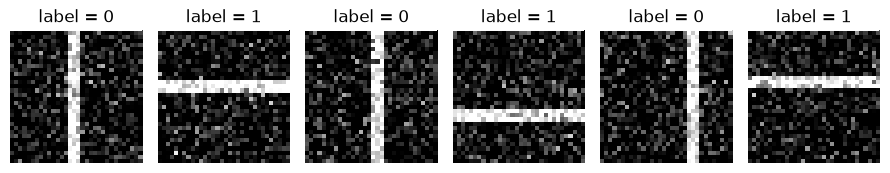

In [91]:
# Synthetic stripes dataset: vertical vs horizontal bright stripe

def make_stripes_dataset(
    n_samples=2400,
    img_size=32,
    stripe_width=3,
    noise_std=0.25,
    seed=SEED,
):
    """Generate a small dataset of noisy stripe images.

    Class 0: vertical bright stripe at a random column.
    Class 1: horizontal bright stripe at a random row.
    """
    rng = np.random.RandomState(seed)
    X = np.zeros((n_samples, 1, img_size, img_size), dtype=np.float32)
    y = np.zeros(n_samples, dtype=np.int64)

    margin = 4  # keep stripes away from the border a bit

    for i in range(n_samples):
        label = rng.randint(0, 2)
        y[i] = label
        img = np.zeros((img_size, img_size), dtype=np.float32)

        if label == 0:
            # vertical stripe
            col = rng.randint(margin, img_size - margin - stripe_width)
            img[:, col:col + stripe_width] = 1.0
        else:
            # horizontal stripe
            row = rng.randint(margin, img_size - margin - stripe_width)
            img[row:row + stripe_width, :] = 1.0

        # Add Gaussian noise and clip to [0, 1]
        img += noise_std * rng.randn(img_size, img_size)
        img = np.clip(img, 0.0, 1.0)
        X[i, 0, :, :] = img

    return X, y


X, y = make_stripes_dataset()

n_total = X.shape[0]
n_train = 2000
n_val = 200
n_test = n_total - n_train - n_val

X_train, y_train = X[:n_train], y[:n_train]
X_val, y_val = X[n_train:n_train + n_val], y[n_train:n_train + n_val]
X_test, y_test = X[n_train + n_val:], y[n_train + n_val:]

print(f"Train size: {len(X_train)}, val size: {len(X_val)}, test size: {len(X_test)}")

# Wrap in PyTorch datasets & loaders
train_ds = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train),
)
val_ds = TensorDataset(
    torch.from_numpy(X_val),
    torch.from_numpy(y_val),
)
test_ds = TensorDataset(
    torch.from_numpy(X_test),
    torch.from_numpy(y_test),
)

batch_size = 64
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

# Quick visualization of a few samples
def show_examples(X, y, n=6):
    plt.figure(figsize=(9, 2))
    for i in range(n):
        ax = plt.subplot(1, n, i + 1)
        ax.imshow(X[i, 0], cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"label = {y[i]}")
        ax.axis("off")
    plt.tight_layout()

show_examples(X_train, y_train)


## Core Task 1 — Convolution output shapes & parameter counts

In the video, you saw that convolutions:

- Use **local receptive fields** instead of full connections.
- Share weights spatially across the image.
- Produce feature maps whose height/width depend on kernel size, stride, and padding.

In this task you will:

1. Implement a small helper to compute the output shape of a 2D convolution.
2. Compare parameter counts for an MLP layer vs a convolutional layer on 32×32 images.


In [92]:
import math

def conv2d_output_shape(h_in, w_in, kernel_size, stride=1, padding=0):
    """Compute output spatial size (H_out, W_out) for a 2D conv layer.

    Uses the standard discrete convolution formula with integer hyperparameters.
    """
    if isinstance(kernel_size, tuple):
        kH, kW = kernel_size
    else:
        kH = kW = kernel_size
    if isinstance(stride, tuple):
        sH, sW = stride
    else:
        sH = sW = stride
    if isinstance(padding, tuple):
        pH, pW = padding
    else:
        pH = pW = padding

    # replace the lines below with the correct formula.
    # Hint: floor division via math.floor is useful here.
    h_out = math.floor((h_in + pH*2 - kH) / sH) + 1 # <-- replace None with an expression in terms of h_in, kH, pH, sH
    w_out = math.floor((w_in + pW*2 - kW) / sW) + 1 # <-- replace None with an expression in terms of w_in, kW, pW, sW

    return h_out, w_out


# Once you have filled in the formula, these sanity checks should make sense:
print("28x28, kernel=5, stride=1, pad=0:", conv2d_output_shape(28, 28, kernel_size=5, stride=1, padding=0))
print("32x32, kernel=3, stride=2, pad=1:", conv2d_output_shape(32, 32, kernel_size=3, stride=2, padding=1))


28x28, kernel=5, stride=1, pad=0: (24, 24)
32x32, kernel=3, stride=2, pad=1: (16, 16)


In [93]:
def count_parameters(module):
    return sum(p.numel() for p in module.parameters() if p.requires_grad)


C, H, W = 1, 32, 32  # our synthetic images are 1×32×32
hidden_units = 128

# Fully connected layer that ignores spatial structure
fc = nn.Linear(C * H * W, hidden_units)

# Convolution layer with small kernel and 16 channels
conv = nn.Conv2d(in_channels=C, out_channels=16, kernel_size=3, stride=1, padding=1)

print("Fully-connected layer parameters:", count_parameters(fc))
print("Convolution layer parameters    :", count_parameters(conv))


Fully-connected layer parameters: 131200
Convolution layer parameters    : 160


👉 **After running the previous cell**, answer briefly:

- Why does the convolutional layer have far fewer parameters than the fully connected one?
- How might this difference affect training speed and overfitting on image tasks?

You can write your answer in a new markdown cell below or as comments in the notebook.


- Why does the convolutional layer have far fewer parameters than the fully connected one?
  - For the convolutional layer, each hidden layer activation only needs `width_kernel` * `height_kernel` parameters, while the fully connected one needs the size of original image. The former one is much smaller than the later one.
- How might this difference affect training speed and overfitting on image tasks?
  - Training speed may reduce a lot on convolutional layer. The connected one may have overfitting problem, since the parameter size is larger than the convolutional one.

## Core Task 2 — Tiny MLP vs tiny CNN on stripes

Now we'll build two small classifiers for the stripe dataset:

- A **TinyMLP** that flattens the image and uses only fully connected layers.
- A **TinyCNN** with convolutions, pooling, and a final fully connected layer.

Your goals:

1. Run both models for a few epochs on the training set.
2. Track training and validation accuracy over time.
3. Compare parameter counts and generalization (validation accuracy).


In [94]:
class TinyMLP(nn.Module):
    def __init__(self, input_shape=(1, 32, 32), hidden_dim=128, num_classes=2):
        super().__init__()
        C, H, W = input_shape
        self.flatten = nn.Flatten()
        self.net = nn.Sequential(
            nn.Linear(C * H * W, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.net(x)


class TinyCNN(nn.Module):
    def __init__(self, input_shape=(1, 32, 32), num_classes=2):
        super().__init__()
        C, H, W = input_shape

        # TODO: feel free to experiment with the channel counts or kernel sizes below.
        self.conv1 = nn.Conv2d(C, 16, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(2)   # 32x32 -> 16x16
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(2)   # 16x16 -> 8x8
        self.relu = nn.ReLU()

        # Compute flattened size after conv/pool stack
        with torch.no_grad():
            dummy = torch.zeros(1, *input_shape)
            h = self._forward_features(dummy)
            self.flatten_dim = h.view(1, -1).shape[1]

        self.fc = nn.Linear(self.flatten_dim, num_classes)

    def _forward_features(self, x):
        x = self.relu(self.conv1(x))
        x = self.pool1(x)
        x = self.relu(self.conv2(x))
        x = self.pool2(x)
        return x

    def forward(self, x):
        x = self._forward_features(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


mlp = TinyMLP(input_shape=(1, 32, 32), hidden_dim=128, num_classes=2).to(device)
cnn = TinyCNN(input_shape=(1, 32, 32), num_classes=2).to(device)

print("TinyMLP parameters:", count_parameters(mlp))
print("TinyCNN parameters:", count_parameters(cnn))


TinyMLP parameters: 131458
TinyCNN parameters: 8898


In [95]:
def run_epoch(model, loader, optimizer=None, loss_fn=None, device="cpu"):
    if optimizer is None:
        model.eval()
    else:
        model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for xb, yb in loader:
        xb = xb.to(device)
        yb = yb.to(device)

        if optimizer is not None:
            optimizer.zero_grad()

        with torch.set_grad_enabled(optimizer is not None):
            logits = model(xb)
            loss = loss_fn(logits, yb) if loss_fn is not None else torch.tensor(0.0, device=device)
            if optimizer is not None:
                loss.backward()
                optimizer.step()

        running_loss += float(loss.item()) * xb.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == yb).sum().item()
        total += xb.size(0)

    avg_loss = running_loss / total
    avg_acc = correct / total
    return avg_loss, avg_acc


def train_model(model, train_loader, val_loader, epochs=5, lr=1e-3, device="cpu"):
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = run_epoch(model, train_loader, optimizer, loss_fn, device=device)
        val_loss, val_acc = run_epoch(model, val_loader, optimizer=None, loss_fn=loss_fn, device=device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch:2d}: "
            f"train_loss={train_loss:.3f}, train_acc={train_acc:.3f} | "
            f"val_loss={val_loss:.3f}, val_acc={val_acc:.3f}"
        )

    return history


In [96]:
# Train the MLP
print("Training TinyMLP...")
mlp_history = train_model(mlp, train_loader, val_loader, epochs=5, lr=1e-3, device=device)

# Train the CNN
print("\nTraining TinyCNN...")
cnn_history = train_model(cnn, train_loader, val_loader, epochs=5, lr=1e-3, device=device)


Training TinyMLP...
Epoch  1: train_loss=0.201, train_acc=0.955 | val_loss=0.008, val_acc=1.000
Epoch  2: train_loss=0.003, train_acc=1.000 | val_loss=0.002, val_acc=1.000
Epoch  3: train_loss=0.001, train_acc=1.000 | val_loss=0.001, val_acc=1.000
Epoch  4: train_loss=0.001, train_acc=1.000 | val_loss=0.001, val_acc=1.000
Epoch  5: train_loss=0.001, train_acc=1.000 | val_loss=0.001, val_acc=1.000

Training TinyCNN...
Epoch  1: train_loss=0.407, train_acc=0.882 | val_loss=0.121, val_acc=0.960
Epoch  2: train_loss=0.028, train_acc=0.998 | val_loss=0.006, val_acc=1.000
Epoch  3: train_loss=0.003, train_acc=1.000 | val_loss=0.002, val_acc=1.000
Epoch  4: train_loss=0.001, train_acc=1.000 | val_loss=0.001, val_acc=1.000
Epoch  5: train_loss=0.001, train_acc=1.000 | val_loss=0.001, val_acc=1.000


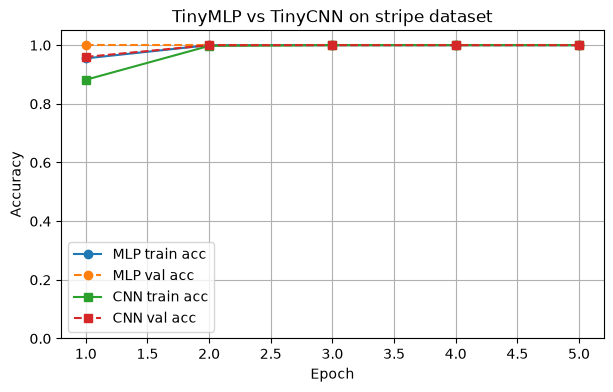

In [97]:
# Plot learning curves for both models

epochs = np.arange(1, len(mlp_history["train_acc"]) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, mlp_history["train_acc"], marker="o", label="MLP train acc")
plt.plot(epochs, mlp_history["val_acc"], marker="o", linestyle="--", label="MLP val acc")
plt.plot(epochs, cnn_history["train_acc"], marker="s", label="CNN train acc")
plt.plot(epochs, cnn_history["val_acc"], marker="s", linestyle="--", label="CNN val acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.ylim(0.0, 1.05)
plt.grid(True)
plt.legend()
plt.title("TinyMLP vs TinyCNN on stripe dataset")
plt.show()


👉 **After looking at the learning curves**, answer:

- Which model reaches higher validation accuracy? By roughly how much?
- Does either model appear to be overfitting or underfitting?
- How do your answers relate to what you know about spatial structure and weight sharing in CNNs?

Again, you can respond in markdown or comments.


- Which model reaches higher validation accuracy? By roughly how much?
  - TinyMLP reaches higher validation accuracy, roughly by

In [98]:
# Quick test-set evaluation

def evaluate_on_test(model, loader, device="cpu"):
    loss_fn = nn.CrossEntropyLoss()
    test_loss, test_acc = run_epoch(model, loader, optimizer=None, loss_fn=loss_fn, device=device)
    print(f"Test loss = {test_loss:.3f}, test accuracy = {test_acc:.3f}")
    return test_loss, test_acc

print("TinyMLP on test:")
mlp_test = evaluate_on_test(mlp, test_loader, device=device)

print("\nTinyCNN on test:")
cnn_test = evaluate_on_test(cnn, test_loader, device=device)


TinyMLP on test:
Test loss = 0.001, test accuracy = 1.000

TinyCNN on test:
Test loss = 0.001, test accuracy = 1.000


## Stretch Tasks (optional, for extra exploration)

If you finish the core tasks early, try one or more of these:

1. **Change the CNN architecture.**
   - Increase or decrease the number of channels (e.g., 8 → 16 or 32 → 64).
   - Remove one pooling layer, or change the kernel size.
   - Re-train and observe how parameter counts and validation accuracy change.

2. **Probe translation robustness.**
   - Write a small function that shifts images a few pixels up/down/left/right.
   - Compare TinyMLP and TinyCNN on these shifted test images.
   - Does the CNN degrade more gracefully than the MLP?

3. **Visualize feature maps.**
   - For a single test image, pass it through `TinyCNN._forward_features`.
   - Plot a few of the resulting feature maps as grayscale images.
   - How do these maps differ between early and later layers?

As you experiment, try to connect your observations back to the ideas from the video:
receptive fields, weight sharing, pooling, and the trade-offs in CNN design.
